In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from analysis.notebooks.components import folder_selection
from susi.io.load_output_data import (
    NetcdfVariablePath,
    StandID,
    load_all_metadatas_from_stands,
    read_netcdf_files_for_selected_variables_from_metadatas,
)

In [27]:
# Define paths
PROJECT_DIRPATH = Path("/home/txart/projects/hiket/susi_26/example_projects/paroninkorpi/")
run_dir  = PROJECT_DIRPATH / "outputs"/"first_test"

In [28]:
# Fancy stand folder picker UI
stand_dropdown = folder_selection.build_dropdown(run_dir, label="stand")

Dropdown(description='stand:', options=(('1', PosixPath('/home/txart/projects/hiket/susi_26/example_projects/p…

# Read data

In [42]:
# Variables to plot, one row each: netcdf path -> row label (with units).
# The C balances are in CO2-equivalents, as in the summary table.
PLOT_VARIABLES:dict[NetcdfVariablePath, str] = {
    NetcdfVariablePath("/stand/volumegrowth"): "Stand growth\n[m³ ha⁻¹ yr⁻¹]",
    NetcdfVariablePath("/stand/harvested_volume"): "Yield (harvested volume)\n[m³ ha⁻¹]",
    NetcdfVariablePath("/strip/dwtyr_latesummer"): "Late summer WT\n[m]",
    NetcdfVariablePath("/balance/C/stand_c_balance_co2eq"): "Ecosystem C balance\n[kg CO₂-eq ha⁻¹ yr⁻¹]",
    NetcdfVariablePath("/balance/C/soil_c_balance_co2eq"): "Soil C balance\n[kg CO₂-eq ha⁻¹ yr⁻¹]",
}

# Load the chosen variables for every scenario of the selected stand.
# Indirect approach: read the metadata.json files --> source the .netcdf paths from there.
# It could be done more directly (e.g., read_value_several_variables_from_single_file(netcdf_filepath, variable_paths))
# but we need the metadata.json anyways to get the simulation starting and ending dates
stand_folderpath = stand_dropdown.value
stand_id = StandID(stand_folderpath.name)
metadata_by_stand = load_all_metadatas_from_stands(folders=[stand_folderpath])
data_store = read_netcdf_files_for_selected_variables_from_metadatas(
    selected_variables=list(PLOT_VARIABLES),
    metadata_by_stand=metadata_by_stand,
)

# Metadata rows come sorted by run timestamp; sort by name instead so that
# related scenarios sit side by side.
scenarios = sorted(data_store.scenarios[stand_id])

# Simulation start year of each scenario, to put calendar years on the x axis
metadata_df = metadata_by_stand[stand_id]
start_year_by_scenario = dict(
    zip(
        metadata_df["scenario_id"],
        pd.to_datetime(metadata_df["simulation_config.start_date"]).dt.year,
    )
)

# Plot timeseries
Figures show:
- Rows: different ecosystem variables
- Columns: different simulated scenarios for the same stand

SUSI simulates stands in a 1D peatland strip delimited by two ditches.
The points show the spatial mean across the strip, and the error bars show the std.


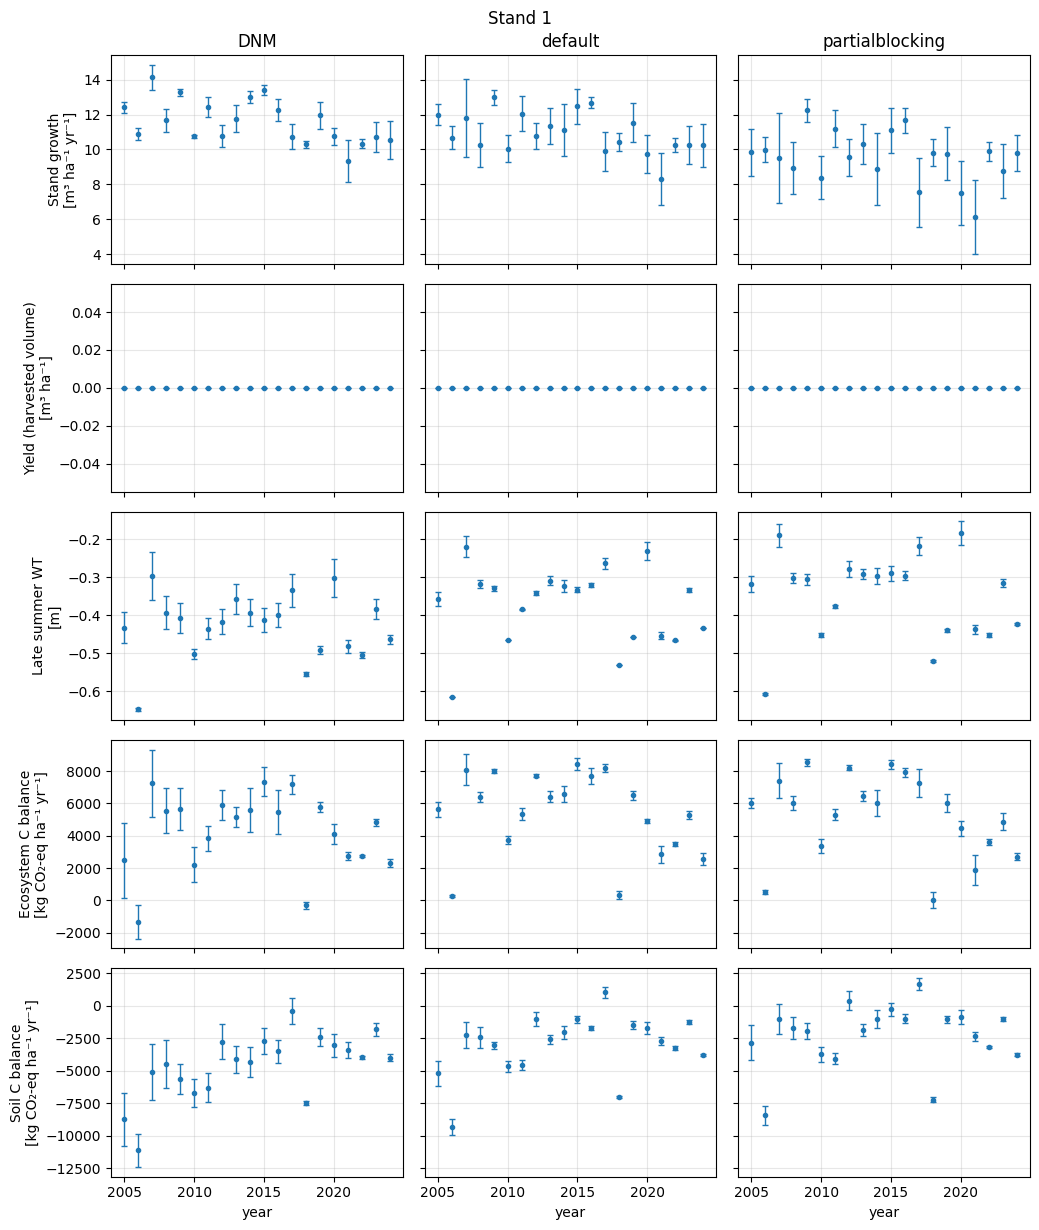

In [43]:
# One row per variable, one column per scenario.
n_rows, n_cols = len(PLOT_VARIABLES), len(scenarios)
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(3.5 * n_cols, 2.5 * n_rows),
    sharex=True,
    sharey="row",
    squeeze=False,  # keep axes 2-D even with a single scenario
)

for row, (var_path, label) in enumerate(PLOT_VARIABLES.items()):
    for col, scenario_id in enumerate(scenarios):
        var_array = data_store.get_variable_value_for_scenario_and_stand(
            var_path, stand_id, scenario_id
        )
        # Timestep 0 is the initial state, saved before the first simulated year
        # (see susi.io.outputs), so it is dropped. After that, timestep i is the
        # end of year start_year + i - 1.
        mean_values = var_array.mean_over_space()[1:] # ready-made method for the mean
        std_values = np.std(var_array.processed, axis=1)[1:] # custom: compute std over space (the strip's columns)
        years = start_year_by_scenario[scenario_id] + np.arange(len(mean_values))
        ax = axes[row, col]
        # Error bars span mean ± 1 std of the spatial variability within the strip
        ax.errorbar(years, mean_values, yerr=std_values, marker=".", capsize=2, linewidth=0, elinewidth=1)
        ax.grid(alpha=0.3)
        if row == 0:
            ax.set_title(scenario_id)
        if col == 0:
            ax.set_ylabel(label)

for ax in axes[-1, :]:
    ax.set_xlabel("year")

fig.suptitle(f"Stand {stand_id}")
fig.tight_layout()
plt.show()